# Pandas Practice: The Iris Dataset

In this notebook you will independently apply everything from `01_Introduction_to_Pandas.ipynb` and `03_Introduction_to_Visualization.ipynb` to a new dataset. The **Iris dataset** is one of the most widely used datasets in data science, it contains measurements (in centimetres) of 150 iris flowers across three species. Your goal is to load it, explore it, answer questions with code, and visualise your findings.

---

![Iris species](../assets/iris.png)

---

In [1]:
# --- Starter code: run this cell first ---
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/iris.csv")
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


## Part 1: Exploring the Data

### Challenge 1: Preview and inspect

Display the first 5 rows and the last 10 rows of the DataFrame.

In [18]:
# YOUR CODE HERE
df.tail(10)
df.head(5)

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


### Challenge 2: How many irises are in the dataset?

How many rows and columns does the DataFrame have?

In [22]:
# YOUR CODE HERE
len(df.count())
df.shape

(150, 5)

### Challenge 3: How many species are there?

Find out how many distinct species exist in the dataset, and what they are called.

In [26]:
# YOUR CODE HERE
df["species"].value_counts()
#df["species"].unique()

Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: species, dtype: int64

---

## Part 2: Statistics

### Challenge 4: Descriptive statistics for petal length

Calculate the mean, median, and mode for `petal_length`. What can you conclude about the distribution?

In [34]:
# YOUR CODE HERE
df["petal_length"].agg(["mean","median"])

mean      3.758667
median    4.350000
Name: petal_length, dtype: float64

In [35]:
df["petal_length"].mode()

0    1.5
Name: petal_length, dtype: float64

### Challenge 5: Range and spread

What is the smallest and largest value for `petal_length`? Calculate the variance and standard deviation.

In [36]:
# YOUR CODE HERE
df["petal_length"].max()

6.9

In [37]:
df["petal_length"].min()

1.0

In [38]:
df["petal_length"].var()

3.113179418344519

In [40]:
df["petal_length"].std()

1.7644204199522626

NOTE: 

What variance and standard deviation mean?

Variance is the average of the squared distances from the mean. 

It measures how spread out the values are, but its units are squared (cm²), which is hard to interpret.

Standard deviation is the square root of the variance. 

It’s in the same units as the data (cm), so it’s easier to read: a typical petal length is about one std away from the mean.

### Challenge 6: Full summary

Use a single command to get the basic descriptive statistics for all columns.

In [45]:
# YOUR CODE HERE
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


### Challenge 7: Overall average sepal length

What is the average `sepal_length` across all 150 flowers?

In [44]:
# YOUR CODE HERE

df["sepal_length"].mean()

5.843333333333334

---

## Part 3: Groupby

### Challenge 8: Count by species

Use `groupby` to count the number of observations for each species.

In [64]:
# YOUR CODE HERE
df.groupby("species").count()

,sepal_length,sepal_width,petal_length,petal_width,petal_area
species,,,,,
Iris-setosa,50,50,50,50,50
Iris-versicolor,50,50,50,50,50
Iris-virginica,50,50,50,50,50


In [65]:
df.groupby("species").size()

species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
dtype: int64

### Challenge 9: Average measurements by species

Use `groupby` to find the average `sepal_length`, `sepal_width`, `petal_length`, and `petal_width` for each species.

In [68]:
# YOUR CODE HERE
df.groupby("species")["sepal_length"].mean()


species
Iris-setosa        5.006
Iris-versicolor    5.936
Iris-virginica     6.588
Name: sepal_length, dtype: float64

In [69]:
df.groupby("species")["sepal_length","sepal_width"].mean()

/var/folders/9h/hbd9g7v966jgt_59027344x80000gn/T/ipykernel_72490/490855964.py:1: FutureWarning: Indexing with multiple keys (implicitly converted to a tuple of keys) will be deprecated, use a list instead.
  df.groupby("species")["sepal_length","sepal_width"].mean()


,sepal_length,sepal_width
species,,
Iris-setosa,5.006,3.418
Iris-versicolor,5.936,2.770
Iris-virginica,6.588,2.974


In [ ]:
df.groupby("species")[["sepal_length","sepal_width"]].mean()

,sepal_length,sepal_width
species,,
Iris-setosa,5.006,3.418
Iris-versicolor,5.936,2.770
Iris-virginica,6.588,2.974


In [73]:
df[["sepal_length","sepal_width"]]

,sepal_length,sepal_width
0,5.1,3.5
1,4.9,3.0
2,4.7,3.2
3,4.6,3.1
4,5.0,3.6
...,...,...
145,6.7,3.0
146,6.3,2.5
147,6.5,3.0
148,6.2,3.4


---

## Part 4: Column Operations and Filtering

### Challenge 10: Add a new column

Create a new column `sepal_total` that is the sum of `sepal_width` and `sepal_length`.

In [47]:
# YOUR CODE HERE
df.eval("`sepal_total`= `sepal_width` + `sepal_length`")

,sepal_length,sepal_width,petal_length,petal_width,species,sepal_total
0,5.1,3.5,1.4,0.2,Iris-setosa,8.6
1,4.9,3.0,1.4,0.2,Iris-setosa,7.9
2,4.7,3.2,1.3,0.2,Iris-setosa,7.9
3,4.6,3.1,1.5,0.2,Iris-setosa,7.7
4,5.0,3.6,1.4,0.2,Iris-setosa,8.6
...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica,9.7
146,6.3,2.5,5.0,1.9,Iris-virginica,8.8
147,6.5,3.0,5.2,2.0,Iris-virginica,9.5
148,6.2,3.4,5.4,2.3,Iris-virginica,9.6


### Challenge 11: Add petal area

Create a new column `petal_area` as a rough estimate of petal area: `petal_length × petal_width`.

In [50]:
# YOUR CODE HERE
df.eval("`petal_area`= `petal_length` * `petal_width`")

,sepal_length,sepal_width,petal_length,petal_width,species,petal_area
0,5.1,3.5,1.4,0.2,Iris-setosa,0.28
1,4.9,3.0,1.4,0.2,Iris-setosa,0.28
2,4.7,3.2,1.3,0.2,Iris-setosa,0.26
3,4.6,3.1,1.5,0.2,Iris-setosa,0.30
4,5.0,3.6,1.4,0.2,Iris-setosa,0.28
...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica,11.96
146,6.3,2.5,5.0,1.9,Iris-virginica,9.50
147,6.5,3.0,5.2,2.0,Iris-virginica,10.40
148,6.2,3.4,5.4,2.3,Iris-virginica,12.42


### Challenge 12: Filter by petal area

Create a new DataFrame containing only the flowers where `petal_area` is greater than 1 cm².

In [55]:
# YOUR CODE HERE
df.eval("`petal_area`= `petal_length` * `petal_width`",inplace=True)
df[df["petal_area"]> 1.0]

,sepal_length,sepal_width,petal_length,petal_width,species,petal_area
50,7.0,3.2,4.7,1.4,Iris-versicolor,6.58
51,6.4,3.2,4.5,1.5,Iris-versicolor,6.75
52,6.9,3.1,4.9,1.5,Iris-versicolor,7.35
53,5.5,2.3,4.0,1.3,Iris-versicolor,5.20
54,6.5,2.8,4.6,1.5,Iris-versicolor,6.90
...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica,11.96
146,6.3,2.5,5.0,1.9,Iris-virginica,9.50
147,6.5,3.0,5.2,2.0,Iris-virginica,10.40
148,6.2,3.4,5.4,2.3,Iris-virginica,12.42


### Challenge 13: Split by species

Create three separate DataFrames, one for each species, using the full dataset.

In [56]:
# YOUR CODE HERE
setosa = df[df["species"] == "setosa"]
versicolor = df[df["species"] == "versicolor"]
virginica = df[df["species"] == "virginica"]

---

## Part 5: Visualisation

### Challenge 14: Histogram of petal length

Create a histogram of `petal_length`. Describe the distribution, is it symmetric, skewed, or does it appear to have multiple peaks?

<AxesSubplot: ylabel='Frequency'>

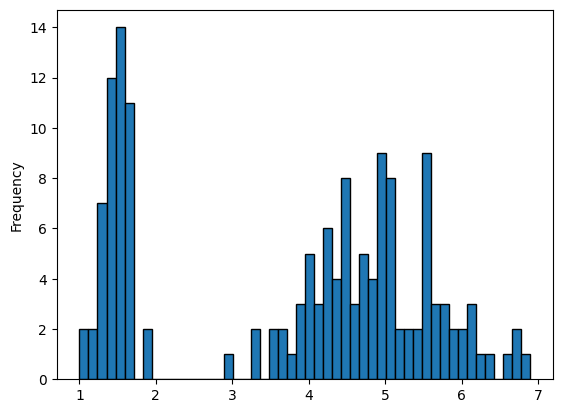

In [59]:
# YOUR CODE HERE
df["petal_length"].plot(kind="hist", bins=50, edgecolor="black")

### Challenge 15: Scatter matrix of petal dimensions

Create a scatter plot of `petal_length` vs `petal_width`. Do larger petals tend to be longer as well?

> Bonus: use `pd.plotting.scatter_matrix(df)` to see all pairwise relationships at once.

<AxesSubplot: xlabel='petal_length', ylabel='petal_width'>

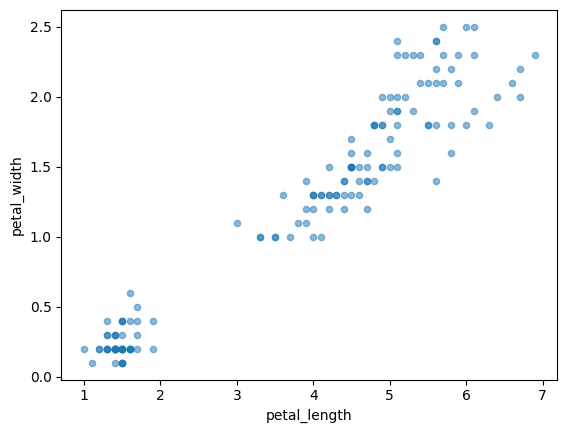

In [62]:

df.plot(kind="scatter",x="petal_length",y="petal_width", alpha=0.5)# YOUR CODE HERE